# Contraste entre bases, múltiplas frequências e enxames simulados — 03/10/2026

Nenhum resultado autoriza declarar este detector confiável. O candidato selecionado falhou nos critérios registrados abaixo.

O candidato escolhido antes do teste foi **ridge_contrast_swarm**. No teste novo: precisão **72.9%**, sensibilidade **10.3%**, especificidade **87.2%**, macro F1 **27.0%**. No Drive: **30/107** janelas detectadas. A rede de controle detectou **5.9%** dos Aedes no mesmo teste. Consulte a comparação pareada e seu intervalo antes de atribuir melhora às estratégias.

## Estratégias implementadas

1. Representação espectral preservando várias linhas: STFT em quadros reais, 2048 amostras/128 de passo a 8 kHz, banda 200–3500 Hz. Contrastes locais em frequência e tempo reduzem componentes suaves; não são prova de invariância a microfone/ruído. A representação é redimensionada; o áudio não é repetido nem preenchido.
2. Contraste supervisionado entre a mesma espécie/táxon em Dryad e HumBug, exigindo grupos de gravação diferentes. O amostrador garante Aedes em ambas as fontes e pares de quatro outros táxons comuns em cada lote. Não aproxima todas as espécies negativas como se fossem uma espécie só. Perda auxiliar de espécie e alinhamento MMD RBF condicionado ao táxon. É uma adaptação inspirada em DR-BioL, não reprodução integral do artigo.
3. Misturas de enxame apenas no treino: até 50% de superposições de gravações da mesma espécie e grupos diferentes, com variação de ganho e coloração. A mistura conserva o rótulo de espécie; não mistura negativos de espécies diferentes e lhes atribui o rótulo do primeiro mosquito. São simulações, não novos indivíduos e não prova de equivalência a enxame real.
4. Trinta e quatro descritores com quatro picos locais e três candidatos de suporte harmônico por quadro, variabilidade temporal, entropia e contagem de picos. SVM e ExtraTrees foram treinados nesses descritores para comparar ML clássico com as redes. Os picos podem mudar de ordem entre quadros; não são trajetórias identificadas de cada indivíduo ou estimativas validadas de fundamental.

Não foram inventadas temperaturas, sexos ou identidades biológicas ausentes. Relações harmônicas não são declaradas invariantes à temperatura ou ao microfone. Separação real de cada mosquito em um único microfone não foi demonstrada.

## Dados e escolha dos modelos

Somente Dryad e HumBug entram no ajuste: 20399 janelas válidas e 628 grupos. Esses grupos não necessariamente equivalem a indivíduos. Mantivemos as divisões existentes por grupo e bytes, com validação e calibração separadas. MosquitoSong, UFRGS, CDMSC e Drive não entram no treino, perdas, normalização aprendida ou limites.

Três redes de 5,65 milhões de parâmetros: controle espectral, contraste e contraste+enxame. Mesmo frontend, arquitetura, amostragem e ruído real de treino; a perda auxiliar de espécie integra o pacote de contraste. Portanto não isolamos cada uma das perdas individualmente. Seeds diferentes são uma limitação desta comparação; não fizemos replicações por seed.

Até 24 épocas, 80 lotes de 96 por época; parada antecipada pela menor AUC ponderada entre fontes na validação. Limite final escolhido somente na calibração para equilibrar o pior recall por fonte/classe com pesos por grupo. Escolha final entre cinco candidatos pela validação, no limite realmente usado. Scores brutos não são probabilidades de acerto. Não ajustamos qualquer parâmetro pelo Drive ou pelo teste novo.

| name                 |   best_epoch |    cut |   validation_precision |   validation_recall |   validation_macro_f1 |   selection_score |
|:---------------------|-------------:|-------:|-----------------------:|--------------------:|----------------------:|------------------:|
| ridge_control        |        4.000 | -0.189 |                  0.196 |               0.714 |                 0.613 |             0.581 |
| ridge_contrast       |        9.000 | -0.829 |                  0.190 |               0.871 |                 0.606 |             0.766 |
| ridge_contrast_swarm |       10.000 | -0.549 |                  0.210 |               0.838 |                 0.626 |             0.800 |
| svm_multipitch       |      nan     | -0.186 |                  0.076 |               0.668 |                 0.446 |             0.664 |
| trees_multipitch     |      nan     |  0.385 |                  0.085 |               0.627 |                 0.475 |             0.684 |

## Teste adquirido depois do congelamento

Seleção fixa de 16 arquivos Aedes aegypti e quatro de cada uma das quatro espécies negativas, todos na fonte acústica D3. Total planejado: 32 arquivos; mantidos: 32; excluídos por fragmentos PCM não constantes já conhecidos: 0. CRC, bytes e fragmentos decodificados comparados com as bases e testes anteriores. Coincidências constantes/silenciosas foram registradas separadamente e não chamadas de duplicação de voo.

São 641 janelas rotuladas, 493 positivas e 148 negativas. O número de janelas não é número de mosquitos. CDMSC não disponibiliza aqui identidade original de indivíduo/sessão; demonstramos novidade de arquivos/fragmentos, não de indivíduos. Rótulos de arquivo não anotam presença de voo em cada janela.

| model                       | selected   |   files |   aedes_precision |   aedes_recall |   aedes_f1 |   specificity |   macro_f1 |   balanced_accuracy |   roc_auc |   true_positive |   known_windows |
|:----------------------------|:-----------|--------:|------------------:|---------------:|-----------:|--------------:|-----------:|--------------------:|----------:|----------------:|----------------:|
| prior_dryad+humbug__svm_rbf | False      |      32 |             0.654 |          0.034 |      0.066 |         0.939 |      0.215 |               0.487 |     0.437 |              32 |             107 |
| prior_dryad__logistic       | False      |      32 |             0.833 |          0.325 |      0.467 |         0.784 |      0.428 |               0.554 |     0.553 |               1 |             107 |
| prior_humbug__svm_rbf       | False      |      32 |             1.000 |          0.010 |      0.020 |         1.000 |      0.199 |               0.505 |     0.483 |              11 |             107 |
| ridge_contrast              | False      |      32 |             0.739 |          0.201 |      0.316 |         0.764 |      0.330 |               0.482 |     0.448 |              34 |             107 |
| ridge_contrast_swarm        | True       |      32 |             0.729 |          0.103 |      0.181 |         0.872 |      0.270 |               0.488 |     0.539 |              30 |             107 |
| ridge_control               | False      |      32 |             0.763 |          0.059 |      0.109 |         0.939 |      0.240 |               0.499 |     0.512 |               7 |             107 |
| svm_multipitch              | False      |      32 |             0.799 |          0.450 |      0.576 |         0.622 |      0.468 |               0.536 |     0.535 |              57 |             107 |
| trees_multipitch            | False      |      32 |             0.749 |          0.284 |      0.412 |         0.682 |      0.374 |               0.483 |     0.512 |              78 |             107 |

Modelos `prior_` são comparações antigas congeladas, não candidatos da seleção atual. A antiga SVM Dryad+HumBug teve bom resultado relativo no Drive; sua comparação aqui é exploratória devido à escolha anterior informada por esse áudio. A SVM HumBug foi o candidato escolhido por validação na rodada anterior.

## Intervalos e comparação pareada

Bootstrap de 2000 reamostragens por arquivo, estratificado pela classe. Todas as previsões usam os mesmos arquivos; as diferenças pareadas reamostram os mesmos grupos. Esses intervalos não medem independência biológica desconhecida e não compensam pouca diversidade de sessões.

| model                | metric            |   lower95 |   upper95 |
|:---------------------|:------------------|----------:|----------:|
| ridge_contrast_swarm | aedes_precision   |     0.554 |     0.879 |
| ridge_contrast_swarm | aedes_recall      |     0.058 |     0.160 |
| ridge_contrast_swarm | aedes_f1          |     0.104 |     0.268 |
| ridge_contrast_swarm | specificity       |     0.750 |     0.932 |
| ridge_contrast_swarm | macro_f1          |     0.162 |     0.354 |
| ridge_contrast_swarm | balanced_accuracy |     0.427 |     0.527 |

| baseline                    | metric            |   mean_delta |   lower95 |   upper95 |
|:----------------------------|:------------------|-------------:|----------:|----------:|
| ridge_control               | aedes_precision   |       -0.020 |    -0.191 |     0.185 |
| ridge_control               | aedes_recall      |        0.045 |     0.014 |     0.076 |
| ridge_control               | aedes_f1          |        0.072 |     0.021 |     0.124 |
| ridge_control               | specificity       |       -0.068 |    -0.129 |    -0.020 |
| ridge_control               | macro_f1          |        0.030 |    -0.001 |     0.061 |
| ridge_control               | balanced_accuracy |       -0.012 |    -0.045 |     0.018 |
| prior_humbug__svm_rbf       | aedes_precision   |       -0.264 |    -0.444 |    -0.109 |
| prior_humbug__svm_rbf       | aedes_recall      |        0.094 |     0.050 |     0.144 |
| prior_humbug__svm_rbf       | aedes_f1          |        0.161 |     0.089 |     0.237 |
| prior_humbug__svm_rbf       | specificity       |       -0.137 |    -0.250 |    -0.068 |
| prior_humbug__svm_rbf       | macro_f1          |        0.071 |     0.029 |     0.117 |
| prior_humbug__svm_rbf       | balanced_accuracy |       -0.022 |    -0.079 |     0.022 |
| prior_dryad+humbug__svm_rbf | aedes_precision   |        0.101 |    -0.167 |     0.520 |
| prior_dryad+humbug__svm_rbf | aedes_recall      |        0.069 |     0.018 |     0.116 |
| prior_dryad+humbug__svm_rbf | aedes_f1          |        0.116 |     0.030 |     0.191 |
| prior_dryad+humbug__svm_rbf | specificity       |       -0.064 |    -0.115 |     0.000 |
| prior_dryad+humbug__svm_rbf | macro_f1          |        0.055 |     0.005 |     0.100 |
| prior_dryad+humbug__svm_rbf | balanced_accuracy |        0.002 |    -0.035 |     0.043 |

## Áudio privado

O usuário identifica o Drive como enxame de Aedes na caixa de vidro. Mantivemos 107 janelas no denominador, incluindo duas inválidas. Sensibilidade nesse áudio não é acurácia binária: faltam negativos para medir falsos positivos. Melhor candidato no Drive, observado depois do congelamento: trees_multipitch, 78/107; não foi promovido por esse resultado. Nenhuma janela privada foi treinada nem distribuída.

## Regressões históricas

As partições antigas de teste/challenge foram reavaliadas apenas depois do congelamento. São resultados retrospectivos: decisões gerais desta pesquisa já foram informadas por avaliações anteriores.

| model                       | scope        |   aedes_precision |   aedes_recall |   specificity |   macro_f1 |   balanced_accuracy |
|:----------------------------|:-------------|------------------:|---------------:|--------------:|-----------:|--------------------:|
| ridge_control               | dryad        |             0.372 |          0.722 |         0.942 |      0.728 |               0.832 |
| ridge_contrast              | dryad        |             0.289 |          0.828 |         0.903 |      0.687 |               0.865 |
| ridge_contrast_swarm        | dryad        |             0.344 |          0.836 |         0.924 |      0.722 |               0.880 |
| svm_multipitch              | dryad        |             0.080 |          0.642 |         0.647 |      0.460 |               0.645 |
| trees_multipitch            | dryad        |             0.092 |          0.622 |         0.705 |      0.489 |               0.664 |
| prior_humbug__svm_rbf       | dryad        |             0.000 |          0.000 |         0.979 |      0.483 |               0.489 |
| prior_dryad+humbug__svm_rbf | dryad        |             0.388 |          0.972 |         0.927 |      0.758 |               0.950 |
| prior_dryad__logistic       | dryad        |             0.224 |          0.964 |         0.840 |      0.638 |               0.902 |
| ridge_control               | humbug       |             0.529 |          0.825 |         0.899 |      0.790 |               0.862 |
| ridge_contrast              | humbug       |             0.545 |          0.870 |         0.900 |      0.804 |               0.885 |
| ridge_contrast_swarm        | humbug       |             0.524 |          0.714 |         0.911 |      0.769 |               0.813 |
| svm_multipitch              | humbug       |             0.219 |          0.643 |         0.689 |      0.560 |               0.666 |
| trees_multipitch            | humbug       |             0.253 |          0.617 |         0.753 |      0.597 |               0.685 |
| prior_humbug__svm_rbf       | humbug       |             0.524 |          0.909 |         0.887 |      0.800 |               0.898 |
| prior_dryad+humbug__svm_rbf | humbug       |             0.534 |          0.922 |         0.890 |      0.806 |               0.906 |
| prior_dryad__logistic       | humbug       |             0.073 |          0.169 |         0.711 |      0.441 |               0.440 |
| ridge_control               | mosquitosong |             1.000 |          0.048 |       nan     |    nan     |             nan     |
| ridge_contrast              | mosquitosong |             1.000 |          0.102 |       nan     |    nan     |             nan     |
| ridge_contrast_swarm        | mosquitosong |             1.000 |          0.037 |       nan     |    nan     |             nan     |
| svm_multipitch              | mosquitosong |             1.000 |          0.216 |       nan     |    nan     |             nan     |
| trees_multipitch            | mosquitosong |             1.000 |          0.099 |       nan     |    nan     |             nan     |
| prior_humbug__svm_rbf       | mosquitosong |             1.000 |          0.017 |       nan     |    nan     |             nan     |
| prior_dryad+humbug__svm_rbf | mosquitosong |             1.000 |          0.122 |       nan     |    nan     |             nan     |
| prior_dryad__logistic       | mosquitosong |             1.000 |          0.477 |       nan     |    nan     |             nan     |
| ridge_control               | ufrgs        |             0.661 |          0.303 |         0.712 |      0.444 |               0.507 |
| ridge_contrast              | ufrgs        |             0.703 |          0.542 |         0.575 |      0.544 |               0.559 |
| ridge_contrast_swarm        | ufrgs        |             0.735 |          0.450 |         0.699 |      0.536 |               0.574 |
| svm_multipitch              | ufrgs        |             0.656 |          0.542 |         0.473 |      0.501 |               0.508 |
| trees_multipitch            | ufrgs        |             0.528 |          0.210 |         0.651 |      0.359 |               0.431 |
| prior_humbug__svm_rbf       | ufrgs        |             0.000 |          0.000 |         0.973 |      0.254 |               0.486 |
| prior_dryad+humbug__svm_rbf | ufrgs        |             0.429 |          0.011 |         0.973 |      0.266 |               0.492 |
| prior_dryad__logistic       | ufrgs        |             0.889 |          0.472 |         0.890 |      0.619 |               0.681 |

## Critérios e conclusão

Exigimos precisão, sensibilidade, especificidade e macro F1 de pelo menos 60%, inclusive limites inferiores de 95% por arquivo. Falhas do candidato escolhido: aedes_precision lower95 below .60, aedes_recall below .60, aedes_recall lower95 below .60, macro_f1 below .60, macro_f1 lower95 below .60.

Um resultado favorável em arquivo novo não comprova robustez a outra população, caixa, sexo ou temperatura. Precisamos de múltiplas sessões de Aedes e outras espécies com a mesma captação, além de controle da caixa vazia, para validar o domínio de uso. Firmware, instalador e checkpoints anteriores foram preservados; não compilamos nem comprimimos nada para Arduino.

![Comparação no teste novo](reports/assets/cross_domain_strategy_comparison.png)

![Confusão e treinamento](reports/assets/cross_domain_strategy_confusion.png)

## Fontes e reprodução

[DR-BioL](https://arxiv.org/html/2510.00346v1): inspiração para contraste e MMD por espécie; arquitetura e alguns objetivos diferem. [Enxames sintéticos, prova de conceito](https://arxiv.org/abs/2512.12365): motivação para simulação, não validação do nosso enxame real. [Sexo e temperatura](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0343060): justificam manter explícitas as variáveis ausentes. [BioDCASE](https://zenodo.org/records/19095788): origem dos novos arquivos acústicos.

Código: `cross_domain_strategy_models.py`, `train_cross_domain_strategies.py`, `fetch_cross_domain_strategy_test.py`, `evaluate_cross_domain_strategies.py`. Resultados e hashes em `results/cross_domain_strategies_2026_10_03/`. Os scripts de treino recusam sobrescrever um experimento congelado; uma nova busca precisa de nova rodada. O notebook apenas lê resultados.


In [1]:
from pathlib import Path
import json, pandas as pd
p=Path('results/cross_domain_strategies_2026_10_03')
for name in ['comparison','historical_metrics','confidence_intervals','paired_comparisons']:
    print(name)
    display(pd.read_csv(p/(name+'.csv')))

comparison


,model,selected,files,aedes_precision,aedes_recall,aedes_f1,specificity,macro_f1,balanced_accuracy,roc_auc,true_positive,known_windows
0,prior_dryad+humbug__svm_rbf,False,32,0.653846,0.034483,0.065511,0.939189,0.214931,0.486836,0.436530,32,107
1,prior_dryad__logistic,False,32,0.833333,0.324544,0.467153,0.783784,0.427881,0.554164,0.553054,1,107
2,prior_humbug__svm_rbf,False,32,1.000000,0.010142,0.020080,1.000000,0.198816,0.505071,0.483458,11,107
3,ridge_contrast,False,32,0.738806,0.200811,0.315789,0.763514,0.330414,0.482162,0.447563,34,107
4,ridge_contrast_swarm,True,32,0.728571,0.103448,0.181172,0.871622,0.270002,0.487535,0.538718,30,107
5,ridge_control,False,32,0.763158,0.058824,0.109228,0.939189,0.239700,0.499006,0.511704,7,107
6,svm_multipitch,False,32,0.798561,0.450304,0.575875,0.621622,0.467977,0.535963,0.535237,57,107
7,trees_multipitch,False,32,0.748663,0.283976,0.411765,0.682432,0.373656,0.483204,0.511513,78,107


historical_metrics


,model,scope,selected,known_windows,unknown_windows,invalid,confusion_rows,confusion_columns,confusion,true_negative,...,non_aedes_f1,macro_f1,balanced_accuracy,emitted_false_positive_rate,coverage,accuracy,roc_auc,average_precision,mcc_on_valid_audio,threshold
0,ridge_control,dryad,False,7901,0,0,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[7103, 438, 0], [100, 260, 0]]",7103,...,0.963511,0.727502,0.832070,0.058082,1.000000,0.931907,0.940597,0.576576,0.488024,-0.188588
1,ridge_contrast,dryad,False,7901,0,0,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[6809, 732, 0], [62, 298, 0]]",6809,...,0.944907,0.686842,0.865354,0.097069,1.000000,0.899506,0.937126,0.540126,0.452565,-0.828987
2,ridge_contrast_swarm,dryad,True,7901,0,0,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[6966, 575, 0], [59, 301, 0]]",6966,...,0.956474,0.721764,0.879931,0.076250,1.000000,0.919757,0.943391,0.652484,0.504690,-0.548639
3,svm_multipitch,dryad,False,7901,0,0,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[4882, 2659, 0], [129, 231, 0]]",4882,...,0.777884,0.460019,0.644530,0.352606,1.000000,0.647133,0.695773,0.101048,0.125154,-0.186393
4,trees_multipitch,dryad,False,7901,0,0,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[5319, 2222, 0], [136, 224, 0]]",5319,...,0.818560,0.489109,0.663783,0.294656,1.000000,0.701557,0.727404,0.118688,0.147754,0.385209
5,prior_humbug__svm_rbf,dryad,False,7901,0,0,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[7382, 159, 0], [360, 0, 0]]",7382,...,0.966041,0.483020,0.489458,0.021085,1.000000,0.934312,0.383028,0.033847,-0.031312,-0.389966
6,prior_dryad+humbug__svm_rbf,dryad,False,7901,0,0,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[6989, 552, 0], [10, 350, 0]]",6989,...,0.961348,0.758012,0.949511,0.073200,1.000000,0.928870,0.983985,0.794766,0.589542,-0.567532
7,prior_dryad__logistic,dryad,False,7901,0,0,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[6337, 1204, 0], [13, 347, 0]]",6337,...,0.912389,0.637775,0.902114,0.159661,1.000000,0.845969,0.956258,0.429700,0.422233,-1.301246
8,ridge_control,humbug,False,1298,0,2,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[1029, 113, 2], [27, 127, 0]]",1029,...,0.935455,0.790062,0.862075,0.098776,0.998459,0.890601,0.937897,0.721269,0.604545,-0.188588
9,ridge_contrast,humbug,False,1298,0,2,"['not_aedes', 'aedes']","['not_aedes', 'aedes', 'invalid']","[[1030, 112, 2], [20, 134, 0]]",1030,...,0.938924,0.804462,0.885240,0.097902,0.998459,0.896764,0.940877,0.847388,0.637060,-0.828987


confidence_intervals


,model,metric,lower95,upper95
0,prior_dryad+humbug__svm_rbf,aedes_precision,0.142619,0.866667
1,prior_dryad+humbug__svm_rbf,aedes_recall,0.003937,0.069310
2,prior_dryad+humbug__svm_rbf,aedes_f1,0.007691,0.127510
3,prior_dryad+humbug__svm_rbf,specificity,0.791187,0.982955
4,prior_dryad+humbug__svm_rbf,macro_f1,0.108399,0.293745
5,prior_dryad+humbug__svm_rbf,balanced_accuracy,0.416206,0.516166
6,prior_dryad__logistic,aedes_precision,0.740741,0.912792
7,prior_dryad__logistic,aedes_recall,0.242717,0.402854
8,prior_dryad__logistic,aedes_f1,0.372210,0.549519
9,prior_dryad__logistic,specificity,0.580645,0.876712


paired_comparisons


,baseline,metric,mean_delta,lower95,upper95
0,ridge_control,aedes_precision,-0.020262,-0.190513,0.184533
1,ridge_control,aedes_recall,0.044632,0.013972,0.076437
2,ridge_control,aedes_f1,0.071892,0.020711,0.123718
3,ridge_control,specificity,-0.068312,-0.129244,-0.020270
4,ridge_control,macro_f1,0.030352,-0.000785,0.061439
5,ridge_control,balanced_accuracy,-0.011840,-0.045418,0.017756
6,prior_humbug__svm_rbf,aedes_precision,-0.263920,-0.444444,-0.108906
7,prior_humbug__svm_rbf,aedes_recall,0.093754,0.049694,0.143744
8,prior_humbug__svm_rbf,aedes_f1,0.160936,0.089412,0.237213
9,prior_humbug__svm_rbf,specificity,-0.137401,-0.250000,-0.067791


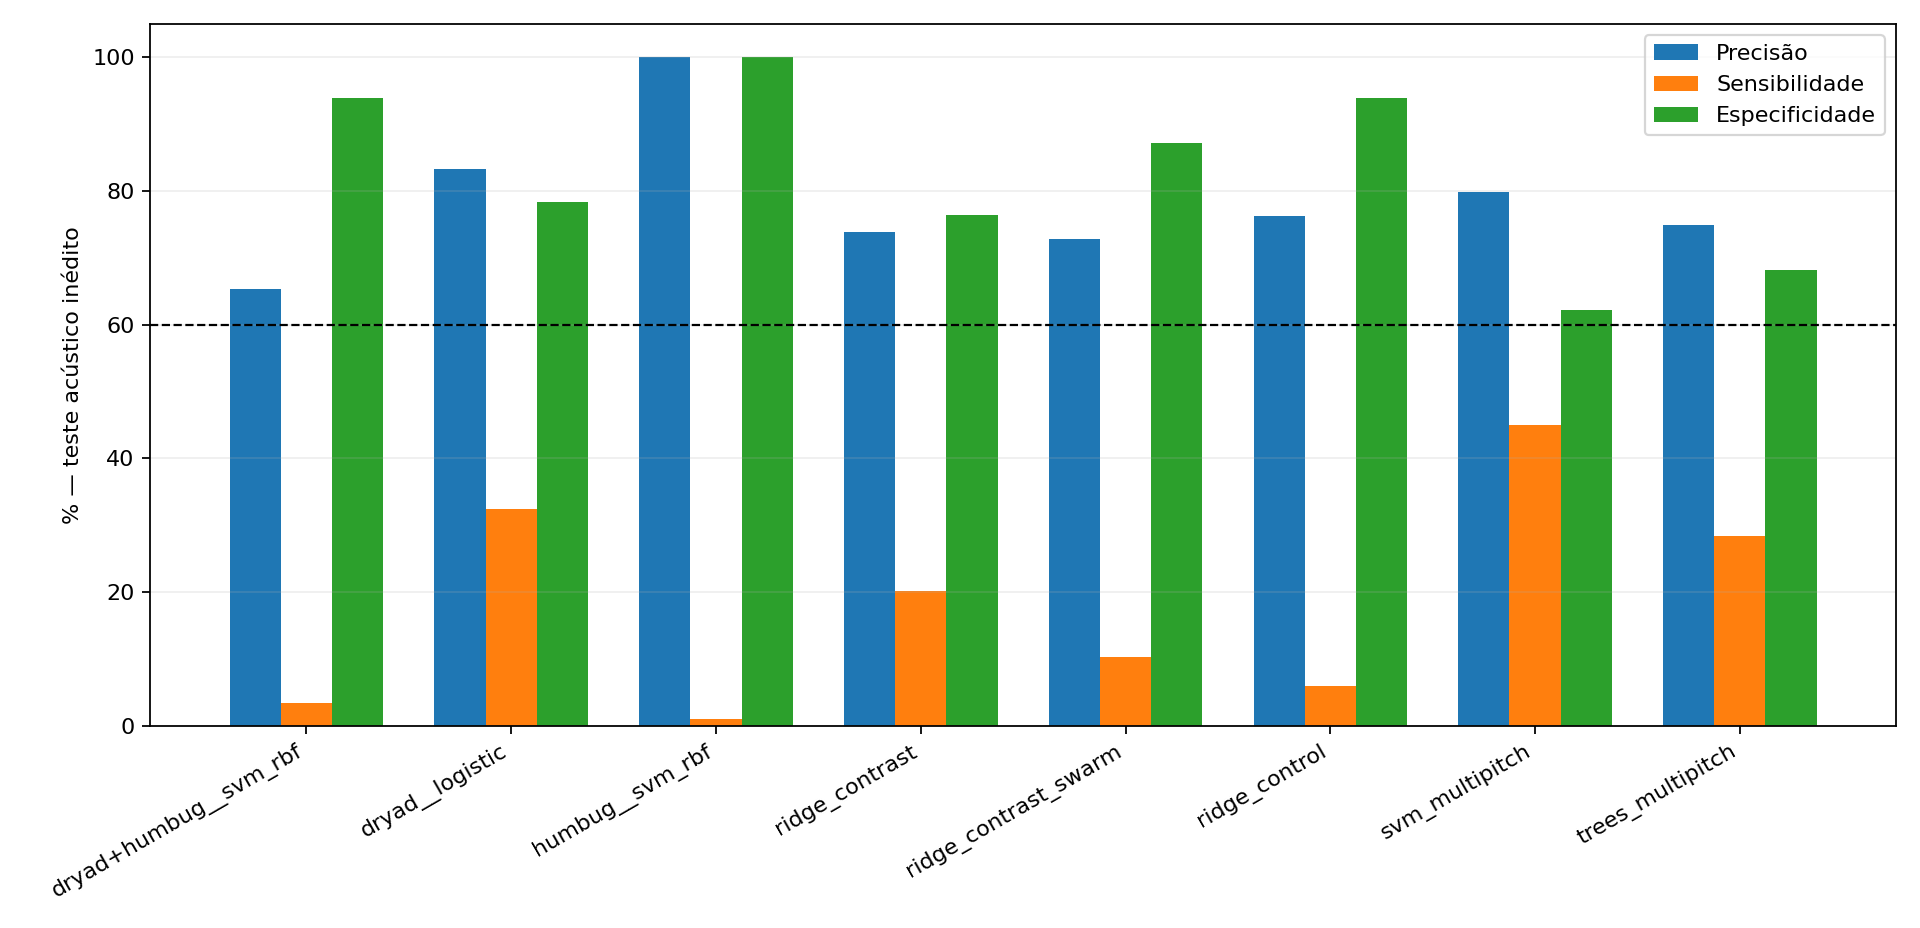

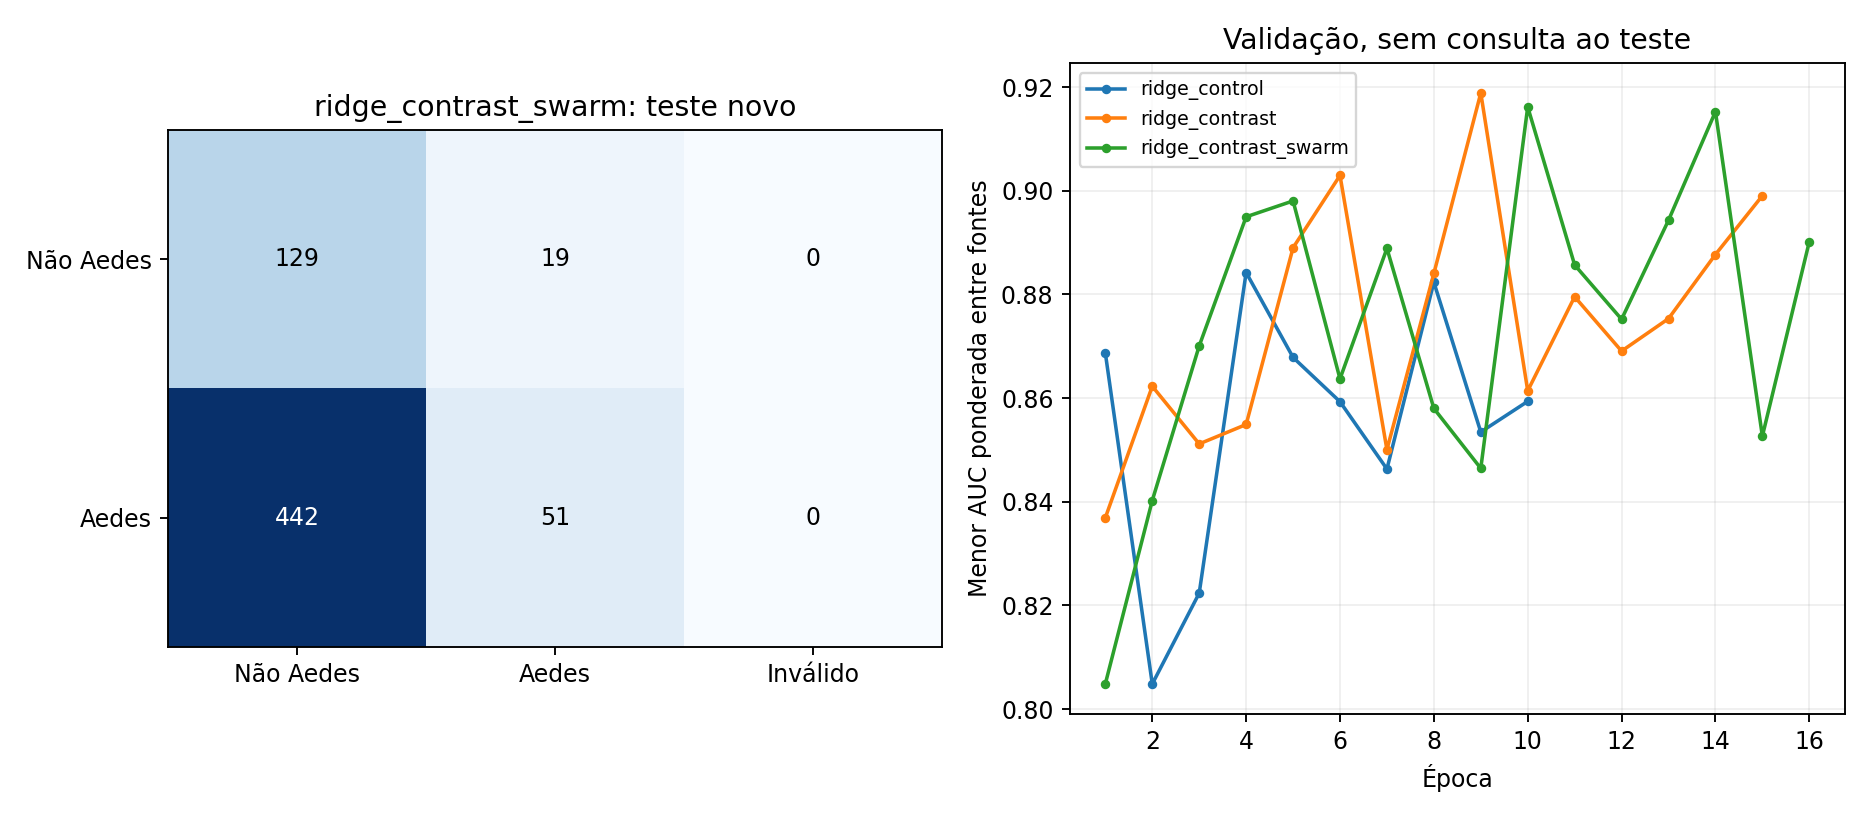

In [2]:
from IPython.display import Image,display
display(Image('reports/assets/cross_domain_strategy_comparison.png'))
display(Image('reports/assets/cross_domain_strategy_confusion.png'))

In [3]:
decision=json.loads((p/'reliability_decision.json').read_text())
display(decision)
audit=pd.read_csv(p/'novelty_audit.csv')
assert (audit.loc[~audit.excluded,'nonconstant_pcm_matches']==0).all()
private=pd.read_csv(p/'drive_positive_control.csv')
assert (private.known_windows==107).all()
assert not decision['arduino_compiled']

{'selected_model': 'ridge_contrast_swarm',
 'reliable': False,
 'failures': ['aedes_precision lower95 below .60',
  'aedes_recall below .60',
  'aedes_recall lower95 below .60',
  'macro_f1 below .60',
  'macro_f1 lower95 below .60'],
 'completed_utc': '2026-10-03T16:50:16.718002+00:00',
 'private_only_positive': True,
 'new_test_files': 32,
 'no_test_tuning': True,
 'baseline_hashes': {'prior_humbug__svm_rbf': '2ec248a8a2cad490502048e59e3782dd73694f3ea266e6674934084394e17f1d',
  'prior_dryad+humbug__svm_rbf': '6f5916e8d3b84207d0627b67854367a1983d646225c63a83d56d8f1f77748367',
  'prior_dryad__logistic': '6e094e79e96b7ce61f05d454e359d99a112ff95dbd19492d718924589b00fa23'},
 'arduino_compiled': False}